# 08 — Business Decision + ROI (Step 9)

**Question:** Who should see the ad so that profit is maximized?

**Three strategies:**
- **A:** show the ad to everyone
- **B:** show it to a random X% of users
- **C:** show it to the model's top X% by uplift (S-Learner). Plus **C′:** the top X% by activity score (simple benchmark)

**Assumptions (Step 1):** ad cost = ₹0.50, visit value = ₹5.

**First, the cost model has to be defined clearly** (the lesson from Step 4):

| Cost model | When you pay | Real world |
|---|---|---|
| **Per impression** (main case) | Only when the ad is actually shown | CPM buying, the display-ad standard |
| Per targeted user | For every targeted user, shown or not | Flat audience fee / data cost |

All numbers are scaled to a population of **1 million users** and come from the **test set** (280,000 users the model never saw).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import AD_COST, VISIT_VALUE
from src.evaluation import targeting_curve, add_profit

FIG = ROOT / "reports" / "figures"
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
POP = 1_000_000
ADJ_SCALE = 0.812 / 1.067        # Step 6: covariate-adjusted lift / unadjusted lift

s = pd.read_parquet(ROOT / "models" / "test_scores.parquet")
y, t, e = s.visit.values, s.treatment.values, s.exposure.values
print(f"Test users: {len(s):,}  |  ITT {y[t==1].mean() - y[t==0].mean():.4%}  |  exposure {e[t==1].mean():.2%}")
print(f"Break-even per impression: lift per exposed user must exceed ₹{AD_COST} / ₹{VISIT_VALUE} = {AD_COST/VISIT_VALUE:.0%}")

Test users: 279,592  |  ITT 1.0661%  |  exposure 3.60%
Break-even per impression: lift per exposed user must exceed ₹0.5 / ₹5.0 = 10%


## 9.1 Targeting curves

For each strategy, measure within the top X% of users from the experiment:
- **itt:** incremental visits per targeted user
- **expo_rate:** impressions per targeted user (how many people will actually see the ad)
- **cace = itt / expo_rate:** extra visits per impression. This is what gets compared with the break-even (10%).

In [2]:
curves = {
    "C: S-Learner (top X%)": targeting_curve(s.score_s_learner, y, t, e),
    "C′: Activity score (top X%)": targeting_curve(s.score_activity, y, t, e),
}
overall = targeting_curve(np.zeros(len(s)), y, t, e).loc[1.0]
rand = pd.DataFrame({"n_users": (curves["C: S-Learner (top X%)"].index * len(s)).astype(int),
                     "itt": overall.itt, "expo_rate": overall.expo_rate,
                     "rate_t": overall.rate_t, "rate_c": overall.rate_c},
                    index=curves["C: S-Learner (top X%)"].index)
curves["B: Random X%"] = rand
for c in curves.values():
    c["cace"] = c.itt / c.expo_rate
pd.concat({k: v.loc[[0.05, 0.1, 0.2, 0.3, 0.5, 1.0], ["itt", "expo_rate", "cace"]] for k, v in curves.items()}, axis=1)

C: S-Learner (top X%)                  C′: Activity score (top X%)  \
                         itt expo_rate   cace                         itt   
share                                                                       
0.0500                0.0920    0.3066 0.2999                      0.0489   
0.1000                0.0550    0.2058 0.2672                      0.0499   
0.2000                0.0407    0.1330 0.3058                      0.0414   
0.3000                0.0309    0.1000 0.3089                      0.0310   
0.5000                0.0205    0.0652 0.3142                      0.0202   
1.0000                0.0107    0.0360 0.2958                      0.0107   

                        B: Random X%                   
       expo_rate   cace          itt expo_rate   cace  
share                                                  
0.0500    0.1807 0.2704       0.0107    0.0360 0.2958  
0.1000    0.1561 0.3197       0.0107    0.0360 0.2958  
0.2000    0.1233 0.3353       0.0107    0.0360 0.2958  
0.3000    0.0949 0.3268       0.0107    0.0360 0.2958  
0.5000    0.0647 0.3129       0.0107    0.0360 0.2958  
1.0000    0.0360 0.2958       0.0107    0.0360 0.2958

**Marginal view:** how much lift per impression do we get from adding the next 10% of users? As long as it stays above
10% (break-even), adding more users is profitable.

In [3]:
def marginal_bins(score, width=0.1):
    order = np.argsort(-np.asarray(score), kind="stable")
    yy, tt, ee = y[order], t[order], e[order]
    n, rows = len(yy), []
    for i in range(int(round(1 / width))):
        sl = slice(int(i * width * n), int((i + 1) * width * n))
        yb, tb, eb = yy[sl], tt[sl], ee[sl]
        itt = yb[tb == 1].mean() - yb[tb == 0].mean()
        ex = eb[tb == 1].mean()
        rows.append({"bin": f"{i*10}-{(i+1)*10}%", "itt": itt, "expo_rate": ex, "marginal_cace": itt / ex if ex > 0 else np.nan})
    return pd.DataFrame(rows).set_index("bin")

marg = marginal_bins(s.score_s_learner)
marg

,itt,expo_rate,marginal_cace
bin,,,
0-10%,0.0550,0.2058,0.2672
10-20%,0.0122,0.0588,0.2073
20-30%,0.0034,0.0334,0.1024
30-40%,0.0015,0.0165,0.0923
40-50%,0.0025,0.0090,0.2807
50-60%,0.0010,0.0240,0.0423
60-70%,0.0004,0.0050,0.0782
70-80%,0.0008,0.0018,0.4186
80-90%,0.0004,0.0019,0.2307


## 9.2 Main case: per-impression cost (₹0.50), visit value ₹5

In [4]:
def profit_tables(ad_cost, cost_model="impression", effect_scale=1.0):
    return {k: add_profit(v, POP, ad_cost, VISIT_VALUE, cost_model, effect_scale) for k, v in curves.items()}

P = profit_tables(AD_COST)
A = P["B: Random X%"].loc[1.0]          # strategy A = everyone (random at 100%)
best = P["C: S-Learner (top X%)"]
x_opt = best.profit.idxmax()
print(f"Strategy A (all users):   profit ₹{A.profit:,.0f}  (cost ₹{A.ad_cost:,.0f}, incr visits {A.incr_visits:,.0f})")
print(f"Strategy C optimum:       target top {x_opt:.0%} -> profit ₹{best.profit.max():,.0f}")
print(f"Strategy C′ optimum:      top {P['C′: Activity score (top X%)'].profit.idxmax():.0%} -> "
      f"₹{P['C′: Activity score (top X%)'].profit.max():,.0f}")

Strategy A (all users):   profit ₹35,284  (cost ₹18,019, incr visits 10,661)
Strategy C optimum:       target top 49% -> profit ₹35,288
Strategy C′ optimum:      top 100% -> ₹35,284


In [5]:
cols = ["targeted_users", "impressions", "ad_cost", "incr_visits", "value", "profit", "roi"]
rows = {"A: Everyone": A[cols]}
for x in [0.1, 0.2, 0.3, 0.5]:
    rows[f"B: Random {x:.0%}"] = P["B: Random X%"].loc[x, cols]
for x in sorted({0.1, 0.2, 0.3, x_opt}):
    rows[f"C: S-Learner top {x:.0%}"] = P["C: S-Learner (top X%)"].loc[x, cols]
    rows[f"C′: Activity top {x:.0%}"] = P["C′: Activity score (top X%)"].loc[x, cols]
strat_tbl = pd.DataFrame(rows).T
strat_tbl.style.format({c: "{:,.0f}" for c in cols[:-1]} | {"roi": "{:.0%}"})

,targeted_users,impressions,ad_cost,incr_visits,value,profit,roi
A: Everyone,"1,000,000","36,038","18,019","10,661","53,303","35,284",196%
B: Random 10%,"100,000","3,604","1,802","1,066","5,330","3,528",196%
B: Random 20%,"200,000","7,208","3,604","2,132","10,661","7,057",196%
B: Random 30%,"300,000","10,811","5,406","3,198","15,991","10,585",196%
B: Random 50%,"500,000","18,019","9,010","5,330","26,651","17,642",196%
C: S-Learner top 10%,"100,000","20,577","10,289","5,498","27,491","17,202",167%
C′: Activity top 10%,"100,000","15,613","7,807","4,992","24,959","17,153",220%
C: S-Learner top 20%,"200,000","26,597","13,298","8,132","40,662","27,364",206%
C′: Activity top 20%,"200,000","24,667","12,334","8,271","41,356","29,022",235%
C: S-Learner top 30%,"300,000","30,009","15,005","9,269","46,346","31,341",209%


### Profit curve

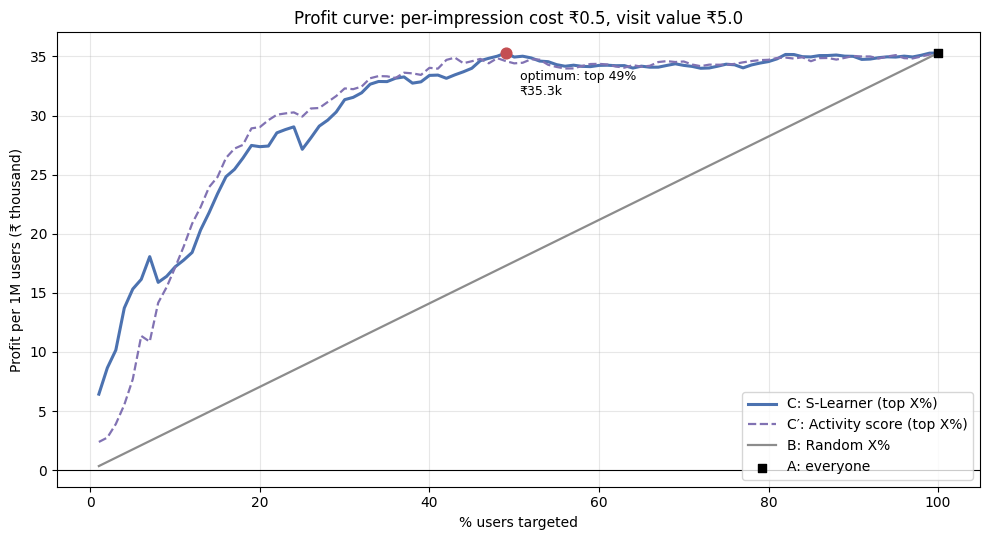

In [6]:
colors = {"C: S-Learner (top X%)": "#4C72B0", "C′: Activity score (top X%)": "#8172B3", "B: Random X%": "#8C8C8C"}

def plot_profit(ax, P, title):
    for k, v in P.items():
        ax.plot(v.index * 100, v.profit / 1000, color=colors[k], lw=2.2 if k.startswith("C:") else 1.6,
                ls="--" if k.startswith("C′") else "-", label=k)
    b = P["C: S-Learner (top X%)"]
    xo = b.profit.idxmax()
    ax.scatter([xo * 100], [b.profit.max() / 1000], color="#C44E52", zorder=5, s=60)
    ax.annotate(f"optimum: top {xo:.0%}\n₹{b.profit.max()/1000:,.1f}k", (xo * 100, b.profit.max() / 1000),
                textcoords="offset points", xytext=(10, -30), fontsize=9)
    a = P["B: Random X%"].loc[1.0]
    ax.scatter([100], [a.profit / 1000], color="black", marker="s", zorder=5, label="A: everyone")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xlabel("% users targeted")
    ax.set_ylabel("Profit per 1M users (₹ thousand)")
    ax.set_title(title)
    ax.grid(alpha=0.3)

fig, ax = plt.subplots(figsize=(10, 5.5))
plot_profit(ax, P, f"Profit curve: per-impression cost ₹{AD_COST}, visit value ₹{VISIT_VALUE}")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG / "08_profit_curve.png", dpi=110)
plt.show()

### How reliable is this optimum? (bootstrap, 300 resamples)
The test set has few control visits, so the profit curve is noisy. Resample the users and see:

In [7]:
rng = np.random.default_rng(42)
idx_t, idx_c = np.where(t == 1)[0], np.where(t == 0)[0]
boot_opt, boot_profit_opt, boot_profit_A, boot_profit_at = [], [], [], {x: [] for x in [0.1, 0.2, 0.3, 0.5]}
for _ in range(300):
    i = np.concatenate([rng.choice(idx_t, len(idx_t)), rng.choice(idx_c, len(idx_c))])
    cv = add_profit(targeting_curve(s.score_s_learner.values[i], y[i], t[i], e[i]), POP, AD_COST, VISIT_VALUE)
    boot_opt.append(cv.profit.idxmax())
    boot_profit_opt.append(cv.profit.max())
    boot_profit_A.append(cv.loc[1.0, "profit"])
    for x in boot_profit_at:
        boot_profit_at[x].append(cv.loc[x, "profit"] - cv.loc[1.0, "profit"])
boot_opt = np.array(boot_opt)
print(f"Optimal X%: median {np.median(boot_opt):.0%}, 80% of resamples between "
      f"{np.percentile(boot_opt, 10):.0%} and {np.percentile(boot_opt, 90):.0%}")
print(f"Profit of A (everyone): 95% CI ₹{np.percentile(boot_profit_A, 2.5):,.0f} – ₹{np.percentile(boot_profit_A, 97.5):,.0f}")
for x, d in boot_profit_at.items():
    d = np.array(d)
    print(f"Top {x:.0%} vs A: profit gain ₹{np.median(d):,.0f}  95% CI [₹{np.percentile(d, 2.5):,.0f}, ₹{np.percentile(d, 97.5):,.0f}]  "
          f"P(gain > 0) = {(d > 0).mean():.0%}")

Optimal X%: median 87%, 80% of resamples between 48% and 100%
Profit of A (everyone): 95% CI ₹25,423 – ₹45,375
Top 10% vs A: profit gain ₹-18,382  95% CI [₹-25,380, ₹-11,369]  P(gain > 0) = 0%
Top 20% vs A: profit gain ₹-7,964  95% CI [₹-12,526, ₹-3,106]  P(gain > 0) = 0%
Top 30% vs A: profit gain ₹-4,226  95% CI [₹-8,311, ₹-900]  P(gain > 0) = 0%
Top 50% vs A: profit gain ₹-2,717  95% CI [₹-5,161, ₹-251]  P(gain > 0) = 1%


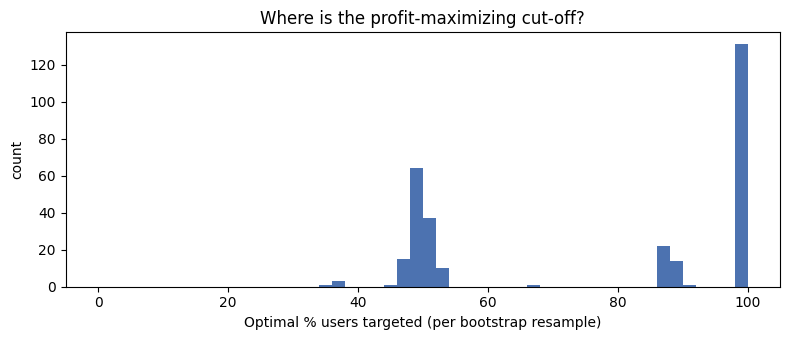

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(boot_opt * 100, bins=np.arange(0, 102, 2), color="#4C72B0")
ax.set_xlabel("Optimal % users targeted (per bootstrap resample)")
ax.set_ylabel("count")
ax.set_title("Where is the profit-maximizing cut-off?")
fig.tight_layout()
fig.savefig(FIG / "08_optimum_bootstrap.png", dpi=110)
plt.show()

## 9.3 Second cost model: ₹0.50 per targeted user

Now every targeted user costs money, whether or not the ad is shown. Each user's incremental visit is ~1%, while break-even is 10%...

In [9]:
P_user = profit_tables(AD_COST, cost_model="user")
for k, v in P_user.items():
    print(f"{k:30s} best profit ₹{v.profit.max():>12,.0f} at {v.profit.idxmax():.0%}   (everyone: ₹{v.loc[1.0,'profit']:,.0f})")
print(f"\nTop 1% by S-Learner: lift per targeted user = {curves['C: S-Learner (top X%)'].loc[0.01, 'itt']:.1%} vs break-even 10%")

C: S-Learner (top X%)          best profit ₹       3,880 at 1%   (everyone: ₹-446,697)
C′: Activity score (top X%)    best profit ₹      -1,556 at 1%   (everyone: ₹-446,697)
B: Random X%                   best profit ₹      -4,467 at 1%   (everyone: ₹-446,697)

Top 1% by S-Learner: lift per targeted user = 17.8% vs break-even 10%


## 9.4 Sensitivity analysis

### (a) Ad cost ₹0.50 → ₹1.00

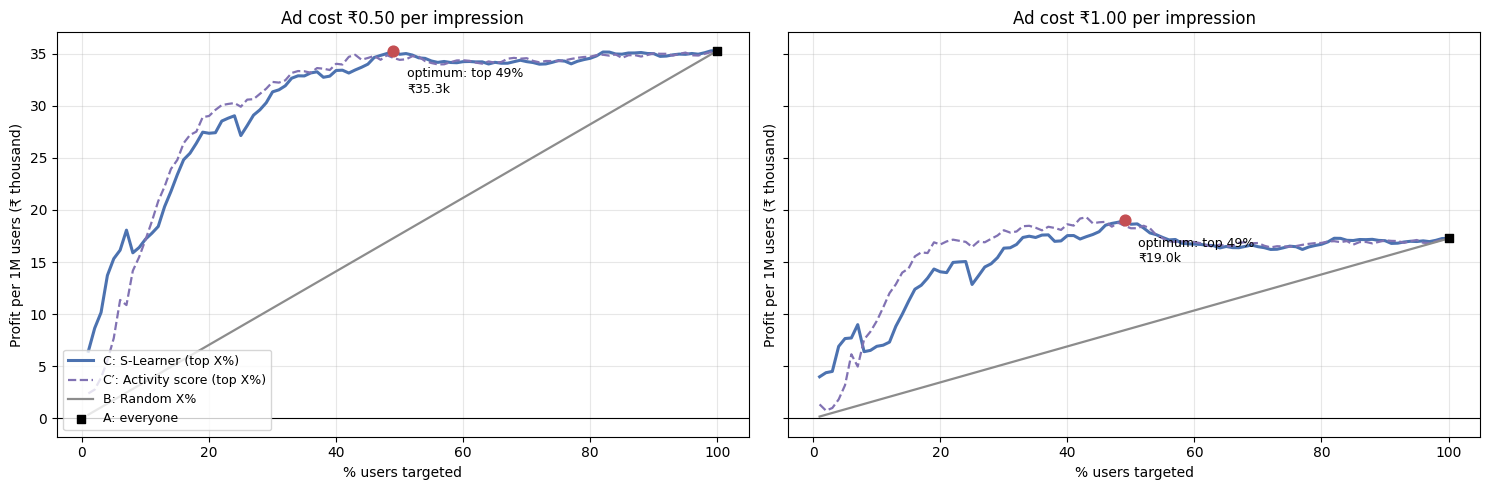

₹0.50: everyone ₹35,284 | best model target top 49% -> ₹35,288 (+0% vs everyone)
₹1.00: everyone ₹17,265 | best model target top 49% -> ₹18,994 (+10% vs everyone)


In [10]:
P1 = profit_tables(1.00)
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
plot_profit(axes[0], P, "Ad cost ₹0.50 per impression")
plot_profit(axes[1], P1, "Ad cost ₹1.00 per impression")
axes[0].legend(loc="lower left", fontsize=9)
fig.tight_layout()
fig.savefig(FIG / "08_sensitivity_cost.png", dpi=110)
plt.show()

for label, PP in [("₹0.50", P), ("₹1.00", P1)]:
    b = PP["C: S-Learner (top X%)"]
    a = PP["B: Random X%"].loc[1.0]
    print(f"{label}: everyone ₹{a.profit:,.0f} | best model target top {b.profit.idxmax():.0%} -> ₹{b.profit.max():,.0f} "
          f"(+{b.profit.max()/a.profit - 1:.0%} vs everyone)")

### (b) The full range of ad costs + covariate-adjusted lift (Step 6)

Step 6 showed that adjusting for the imbalance could cut the lift by ~24%. So each cost is run under two scenarios:
unadjusted (×1.0) and conservative (×0.76).

In [11]:
rows = []
for cost in [0.25, 0.50, 0.75, 1.00, 1.25, 1.50, 2.00, 2.50]:
    for scen, sc in [("unadjusted", 1.0), ("adjusted ×0.76", ADJ_SCALE)]:
        PP = profit_tables(cost, effect_scale=sc)
        b, a = PP["C: S-Learner (top X%)"], PP["B: Random X%"].loc[1.0]
        xo = b.profit.idxmax()
        rows.append({"ad cost (₹)": cost, "scenario": scen, "A: everyone profit": a.profit,
                     "best X%": xo, "C: best profit": b.profit.max(),
                     "cost saved vs A": 1 - b.loc[xo, "ad_cost"] / a.ad_cost,
                     "incr visits kept": b.loc[xo, "incr_visits"] / a.incr_visits,
                     "break-even lift/impression": cost / VISIT_VALUE})
sens = pd.DataFrame(rows).set_index(["ad cost (₹)", "scenario"])
sens.style.format({"A: everyone profit": "₹{:,.0f}", "C: best profit": "₹{:,.0f}", "best X%": "{:.0%}",
                   "cost saved vs A": "{:.0%}", "incr visits kept": "{:.0%}", "break-even lift/impression": "{:.0%}"})

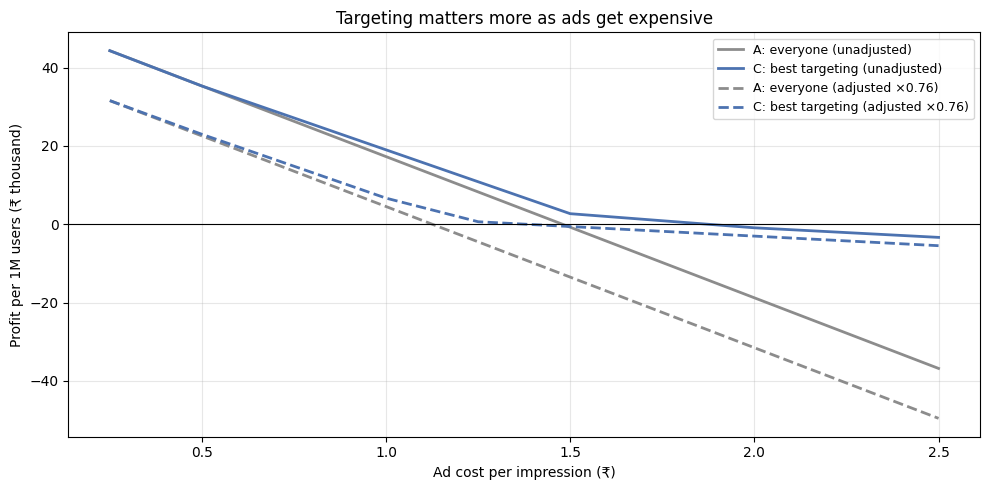

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
for scen, ls in [("unadjusted", "-"), ("adjusted ×0.76", "--")]:
    d = sens.xs(scen, level="scenario")
    ax.plot(d.index, d["A: everyone profit"] / 1000, ls=ls, color="#8C8C8C", lw=2, label=f"A: everyone ({scen})")
    ax.plot(d.index, d["C: best profit"] / 1000, ls=ls, color="#4C72B0", lw=2, label=f"C: best targeting ({scen})")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Ad cost per impression (₹)")
ax.set_ylabel("Profit per 1M users (₹ thousand)")
ax.set_title("Targeting matters more as ads get expensive")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "08_sensitivity_range.png", dpi=110)
plt.show()

## 9.5 Recommendation (numbers auto-generated)

The profit-maximizing X changes with the cost, and the bootstrap shows that the exact optimum is noisy. So we pick a **robust policy**
that does well across all realistic scenarios: **the top 50% by uplift score**. Below: how it compares with "show everyone" at each cost:

In [13]:
X_REC = 0.50
rows = []
for cost in [0.50, 0.75, 1.00, 1.25, 1.50]:
    for scen, sc in [("unadjusted", 1.0), ("adjusted ×0.76", ADJ_SCALE)]:
        PP = profit_tables(cost, effect_scale=sc)
        b, a = PP["C: S-Learner (top X%)"], PP["B: Random X%"].loc[1.0]
        r = b.loc[X_REC]
        rows.append({"ad cost (₹)": cost, "scenario": scen, "A: everyone": a.profit, "C: top 50%": r.profit,
                     "C: best possible": b.profit.max(), "gain vs A": r.profit - a.profit})
rec = pd.DataFrame(rows).set_index(["ad cost (₹)", "scenario"])
display(rec.style.format("₹{:,.0f}"))

r = P["C: S-Learner (top X%)"].loc[X_REC]
r1 = P1["C: S-Learner (top X%)"].loc[X_REC]
A1 = P1["B: Random X%"].loc[1.0]
print(f"Top {X_REC:.0%} by S-Learner uplift score (per-impression buying):")
print(f"  Ad spend falls by {1 - r.ad_cost / A.ad_cost:.0%} while keeping {r.incr_visits / A.incr_visits:.0%} of incremental visits.")
print(f"  At ₹0.50: profit ₹{r.profit:,.0f} vs ₹{A.profit:,.0f} for everyone ({r.profit / A.profit - 1:+.0%}; ROI {r.roi:.0%} vs {A.roi:.0%}).")
print(f"  At ₹1.00: profit ₹{r1.profit:,.0f} vs ₹{A1.profit:,.0f} ({r1.profit / A1.profit - 1:+.0%}).")
print(f"  Bootstrap: top 50% vs everyone at ₹0.50 -> gain 95% CI "
      f"[₹{np.percentile(boot_profit_at[0.5], 2.5):,.0f}, ₹{np.percentile(boot_profit_at[0.5], 97.5):,.0f}]")

Top 50% by S-Learner uplift score (per-impression buying):
  Ad spend falls by 9% while keeping 96% of incremental visits.
  At ₹0.50: profit ₹34,944 vs ₹35,284 for everyone (-1%; ROI 214% vs 196%).
  At ₹1.00: profit ₹18,633 vs ₹17,265 (+8%).
  Bootstrap: top 50% vs everyone at ₹0.50 -> gain 95% CI [₹-5,161, ₹-251]


## 9.6 Save the curves for the app (Step 10)

In [14]:
save = pd.concat({k.split(":")[0]: v[["n_users", "itt", "expo_rate"]] for k, v in curves.items()}, names=["strategy", "share"]).reset_index()
save.to_parquet(ROOT / "models" / "targeting_curves.parquet", index=False)
save.groupby("strategy").size()

strategy
B     100
C     100
C′    100
dtype: int64

## Key takeaways (Step 9)

1. **The cost model changes everything.**
   - **Per targeted user (₹0.50):** showing everyone loses ₹4.47 lakh per 1 million users. Even the model's top 1% earns only ~₹3.9k (noise level).
     Each user's lift (~1%, and only 17.8% even in the top 1%) is near or below the 10% break-even. **Do not run the campaign at this pricing.**
   - **Per impression (₹0.50):** the campaign is very profitable. Showing everyone earns **₹35.3k per 1 million users, ROI ~196%**.
2. **At ₹0.50 per impression targeting does not pay: show everyone.** The lift per impression (CACE ~30%) is above the break-even (10%)
   in almost every segment. On top of that, CPM pricing charges only when the ad is shown, and the ad is already shown mostly to active users,
   so the pricing itself acts as a form of targeting. In the bootstrap every cut-off earns **less** than showing everyone:
   top 10% −₹18k, top 30% −₹4k, top 50% −₹2.7k (95% CI [−₹5.2k, −₹0.3k]).
3. **Targeting pays off when ads get expensive:**
   - ₹1.00: top 50% → +8% profit vs everyone (more in the adjusted scenario)
   - ₹1.50: showing everyone **loses money**, but the top ~50% is **profitable**. Here targeting turns a loss into a profit.
   - ₹2.00+: no strategy is meaningfully profitable. Stop the campaign or lower the bid.
4. **The top-50% trade-off:** ad spend drops 9% while 96% of incremental visits are kept. The bottom 50% of users rarely see the ad
   and their lift is close to zero. But the little lift that exists there still earns more than its cost at ₹0.50.
5. **The activity score is just as good** (as in Step 8). In profit, the S-Learner and the activity score are almost equal.
   A simple rule would work in production too; the uplift model's edge is small.
6. **Conservative scenario (lift ×0.76, the Step 6 imbalance):** at ₹0.50 profit falls to ₹22.5k, but the decision stays the same.
   From ₹1.25 up, targeting becomes even more important.

### Final recommendation
> **Buy ads per impression (CPM). Whether to target depends on the CPM:**
>
> | Cost per impression | Decision | Profit per 1 million users |
> |---|---|---|
> | < ₹0.75 | **Show everyone** (targeting lowers profit) | ~₹35k at ₹0.50, ROI ~196% |
> | ₹0.75 – ₹1.50 | **Target the top 50% by uplift**: 9% lower ad cost, 96% of incremental visits kept | ~₹18.6k at ₹1.00 (+8% vs everyone); loss → profit at ₹1.50 |
> | ≥ ₹2.00 | **Do not run the campaign** (or lower the bid) | every strategy loses money or earns ~0 |
>
> Under per-user pricing this campaign is never profitable. The uplift model's value is not at the assumed ₹0.50 cost
> but as protection when costs rise.

**Caveats:** ad cost and visit value are assumptions; the test set has few control visits (wide bootstrap CIs on the profit curves);
exposure patterns may change once targeting is applied (auction dynamics), so any rollout must keep a holdout control group (Step 11).